## RFM customer segmentation: a classic marketing analytics technique.

## The question is: which customers are worth the most, and which are slipping away?

## You answer it by scoring every customer on three things:

## Recency: how many days since their last purchase (lower is better)

## Frequency: how many distinct orders they’ve placed

## Monetary: how much total money they’ve spent

In [1]:
import re
import numpy as np
import pandas as pd

 ## PART 1: Load and profile

In [2]:
raw= pd.read_csv(r"C:\Users\reema\Downloads\notebooks\raw_transactions.csv", dtype=str, encoding="latin-1")

In [3]:
print(raw.shape)
print(raw.isna().sum())          # missing values?

(44287, 8)
InvoiceNo        0
StockCode        0
Description      0
Quantity         0
InvoiceDate      0
UnitPrice        4
CustomerID     640
Country          0
dtype: int64


In [4]:
print(raw["CustomerID"].value_counts().head())   # is any weird value very frequent?

CustomerID
12654.0    178
12507.0    177
13009.0    163
12216.0    161
12555.0    160
Name: count, dtype: int64


In [5]:
print(raw.duplicated().sum())             # are there duplicates 
print(raw[raw.duplicated(keep=False)].sort_values(list(raw.columns)).head(10))  

200
      InvoiceNo StockCode  Description Quantity      InvoiceDate UnitPrice  \
11234    536392   SKU0084   PRODUCT 84        8  12/1/2011 16:57      1.18   
12102    536392   SKU0084   PRODUCT 84        8  12/1/2011 16:57      1.18   
13813    536396   SKU0052   PRODUCT 52        4    8/8/2011 8:01      0.98   
29739    536396   SKU0052   PRODUCT 52        4    8/8/2011 8:01      0.98   
24858    536452   SKU0119  PRODUCT 119        1   9/9/2011 15:13       2.3   
26949    536452   SKU0119  PRODUCT 119        1   9/9/2011 15:13       2.3   
3940     536546   SKU0084   PRODUCT 84        7   8/8/2011 17:09      1.18   
30890    536546   SKU0084   PRODUCT 84        7   8/8/2011 17:09      1.18   
35105    536553   SKU0292  PRODUCT 292        7   5/30/2011 8:52      7.61   
35129    536553   SKU0292  PRODUCT 292        7   5/30/2011 8:52      7.61   

      CustomerID         Country  
11234    12002.0  United Kingdom  
12102    12002.0  United Kingdom  
13813    12003.0  United Kingdom

In [6]:
raw.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,540367,SKU0085,PRODUCT 85,6,6/13/2011 12:55,3.82,12734.0,United Kingdom
1,542475,SKU0060,PRODUCT 60,3,10/8/2011 8:10,0.84,13135.0,United Kingdom
2,540781,SKU0063,PRODUCT 63,1,2/18/2011 11:42,4.1,12820.0,United Kingdom
3,542179,SKU0144,PRODUCT 144,11,10/29/2011 13:38,1.54,13080.0,United Kingdom
4,539376,SKU0145,PRODUCT 145,2,11/9/2011 10:09,2.03,12555.0,EIRE
5,537280,SKU0245,PRODUCT 245,9,11/5/2011 17:36,1.1,12180.0,United Kingdom
6,538041,SKU0239,PRODUCT 239,6,8/19/2011 14:54,1.88,12331.0,United Kingdom
7,537568,SKU0233,PRODUCT 233,1,12/27/2010 8:02,6.32,12230.0,United Kingdom
8,543194,SKU0218,PRODUCT 218,3,8/6/2011 11:59,2.44,13258.0,United Kingdom
9,537199,SKU0073,PRODUCT 73,5,11/11/2011 15:56,3.85,12165.0,EIRE


# ## PART 2: Cleaning
# One rule per finding. After each rule we record how many rows it removed,
# so at the end every lost row is accounted for.

In [7]:
log = []                                   # (step, removed, left)

def record(step, before, after):
    log.append({"step": step, "removed": before - after, "left": after})    # record whats removed

df = raw.copy()
df.columns = [c.strip() for c in df.columns]  #chop off any invisible spaces at the start or end of the name.
record("loaded", len(df), len(df))

# ### 2.1 Fix types
# QUESTION: can every column be read as the type it should be?
# DECIDE: coerce. Bad values become NaN/NaT so we can count them, not crash.

In [8]:
df["InvoiceNo"] = df["InvoiceNo"].str.strip()   #strip spaces
df["StockCode"] = df["StockCode"].str.strip().str.upper()   # strip spaces + make upper


#everything else should be a string!
df["Quantity"]  = pd.to_numeric(df["Quantity"],  errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], format="%m/%d/%Y %H:%M", errors="coerce")


print(df.dtypes)

InvoiceNo                 str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID                str
Country                   str
dtype: object


# ### 2.2 Rows we cannot trust (bad date / quantity / price)


This block of code identifies and removes rows that are missing core transactional 
data. If a row is missing the date it happened, the amount bought, or the price 
paid, the record is useless for calculating RFM metrics and must be dropped.

In [9]:
bad = df[df[["InvoiceDate", "Quantity", "UnitPrice"]].isna().any(axis=1)]   # if any of them is nan/nat print the row
print(bad)                                  

      InvoiceNo StockCode  Description  Quantity         InvoiceDate  \
115      541494   SKU0051   PRODUCT 51         4 2011-09-26 13:22:00   
7074     536447   SKU0208  PRODUCT 208         2 2010-12-23 08:44:00   
12453    541528   SKU0287  PRODUCT 287         4                 NaT   
27395    537121   SKU0180  PRODUCT 180         1                 NaT   
29435    538327   SKU0286  PRODUCT 286        13                 NaT   
34834    542276   SKU0010   PRODUCT 10         6 2011-10-10 15:21:00   
35493    540667   SKU0037   PRODUCT 37        11                 NaT   
38754    540268   SKU0298  PRODUCT 298         6 2011-02-24 14:17:00   

       UnitPrice CustomerID         Country  
115          NaN    12954.0  United Kingdom  
7074         NaN    12014.0  United Kingdom  
12453       2.82    12961.0  United Kingdom  
27395       6.78    12150.0  United Kingdom  
29435       3.27    12376.0  United Kingdom  
34834        NaN    13100.0  United Kingdom  
35493       1.51    12799.0  

In [10]:
n = len(df)   #drop them
df = df.dropna(subset=["InvoiceDate", "Quantity", "UnitPrice"])

In [11]:
record("unparseable date/qty/price", n, len(df))    #record the dropped
assert log[-1]["removed"] == 8

# ### 2.3 Missing CustomerID
# QUESTION: can we segment a customer we cannot identify? No -> drop.

RFM (Recency, Frequency, Monetary) segmentation is fundamentally tied to individual user behavior. If a transaction does not have 
an attached Customer ID, it is physically impossible to track that customer's purchase history or assign them to a segment. Therefore, anonymous rows must be dropped.

In [12]:
n = len(df)
df = df.dropna(subset=["CustomerID"])
record("missing CustomerID", n, len(df))
assert log[-1]["removed"] == 640

# ### 2.4 Exact duplicates
# Note: 200 duplicates existed in the RAW file, but 4 were already removed by
# earlier steps, so only 196 remain here. Order of steps changes the counts.

In [13]:
print("duplicates now:", df.duplicated().sum())

duplicates now: 196


In [14]:
n = len(df)
df = df.drop_duplicates()
record("duplicate rows", n, len(df))
assert log[-1]["removed"] == 196

# ### 2.5 Cancellations ("C" invoices)
# QUESTION: what are they? Check they are returns (negative quantity).
# DECIDE: remove from spend, but KEEP them to count returns per customer later.

In [15]:
is_cancel = df["InvoiceNo"].str.startswith("C", na=False)   # any invoiceno starting with C 
print("share with negative qty:", (df.loc[is_cancel, "Quantity"] < 0).mean().round(3))   # proof by seeing if their quantities are negative
print(df[is_cancel].head(3))

share with negative qty: 0.999
    InvoiceNo StockCode  Description  Quantity         InvoiceDate  UnitPrice  \
10    C544129   SKU0131  PRODUCT 131        -5 2011-11-03 10:18:00       1.04   
91    C540444   SKU0201  PRODUCT 201       -51 2011-10-15 11:04:00       7.28   
124   C540890   SKU0003    PRODUCT 3        -3 2011-12-02 14:02:00       5.25   

    CustomerID         Country  
10     13420.0  United Kingdom  
91     12742.0  United Kingdom  
124    12839.0          France  


In [16]:
print(is_cancel.sum())

1594


In [17]:
cancellations = df[is_cancel].copy()        # keep for n_cancellations
n = len(df)
df = df[~is_cancel]   # only keep rows that are NOT cancel
record("cancellation invoices", n, len(df))
assert log[-1]["removed"] == 1594

# ### 2.6 Impossible values (quantity <= 0 or price <= 0)
# Check what is left AFTER cancellations, so we don't blame the wrong rows.

In [18]:
print("qty<=0  :", (df["Quantity"] <= 0).sum())
print("price<=0:", (df["UnitPrice"] <= 0).sum())

qty<=0  : 0
price<=0: 37


In [19]:
n = len(df)
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
record("qty<=0 or price<=0", n, len(df))
assert log[-1]["removed"] == 37

# ### 2.7 Non-product lines (postage, fees, manual entries)
# QUESTION: which stock codes don't follow the normal pattern SKU + digits?

In [20]:
not_normal = ~df["StockCode"].str.match(r"^SKU\d+$")
print(df.loc[not_normal, "StockCode"].value_counts())

StockCode
M               16
POST            15
DOT             13
BANK CHARGES    12
Name: count, dtype: int64


In [21]:
NON_PRODUCT = {"POST", "DOT", "M", "BANK CHARGES", "C2", "D", "S", "B",
               "AMAZONFEE", "CRUK", "PADS"}
n = len(df)
df = df[~df["StockCode"].isin(NON_PRODUCT)]
record("non-product codes", n, len(df))
assert log[-1]["removed"] == 56

# ### 2.8 Outliers (the 25,000-unit line)
# QUESTION: what do line totals look like? Money is right-skewed, so a plain
# IQR fence on raw values would cut real big orders. Use the log scale.
# Fence = Q3 + 3 * IQR  (3 = "extreme" outliers only; 1.5 is too aggressive).

In [22]:
df = df.assign(TotalPrice=df["Quantity"] * df["UnitPrice"])
print(df["TotalPrice"].describe())
print(df["TotalPrice"].nlargest(5))          # the monsters

count    41756.000000
mean        25.382157
std        376.625125
min          0.450000
25%          5.200000
50%         11.180000
75%         24.720000
max      52500.000000
Name: TotalPrice, dtype: float64
33641    52500.0
41489    52500.0
8323     18900.0
39163     1453.9
6378      1337.6
Name: TotalPrice, dtype: float64


In [23]:
log_total = np.log1p(df["TotalPrice"])
q1, q3 = log_total.quantile([0.25, 0.75])
fence = q3 + 3.0 * (q3 - q1)

In [24]:
n = len(df)
df = df[log_total <= fence]
record("extreme outlier lines", n, len(df))

# ### 2.9 Cleaning report: every lost row accounted for

In [25]:
report = pd.DataFrame(log)
print(report.to_string(index=False))

                      step  removed  left
                    loaded        0 44287
unparseable date/qty/price        8 44279
        missing CustomerID      640 43639
            duplicate rows      196 43443
     cancellation invoices     1594 41849
        qty<=0 or price<=0       37 41812
         non-product codes       56 41756
     extreme outlier lines        3 41753


# ## PART 3: RFM metrics
# QUESTION: what is "now"? Not today's date, or Recency would be ~15 years for
# 2011 data. Use the day AFTER the last transaction.

In [26]:
#normalize-> to midnight   
# shift by one day
snapshot = df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1) 

In [27]:
print("snapshot:", snapshot)

snapshot: 2011-12-09 00:00:00


In [28]:
print(df["InvoiceDate"].max())

2011-12-08 11:04:00


In [29]:
assert snapshot == pd.Timestamp("2011-12-09")

# ### 3.1 One groupby object, reused for everything

In [30]:
g = df.groupby("CustomerID")

rfm = pd.DataFrame({
    "Recency":   (snapshot - g["InvoiceDate"].max()).dt.days,   # days since last purchase
    "Frequency": g["InvoiceNo"].nunique(),                      # ORDERS, not rows
    "Monetary":  g["TotalPrice"].sum().round(2),
})
print(rfm.head())

            Recency  Frequency  Monetary
CustomerID                              
12000.0          38          7   1082.92
12001.0         253          1     81.84
12002.0           7         19   2930.67
12003.0          79         12   1092.51
12004.0         111          7    851.32


In [31]:
print(rfm.describe())

           Recency    Frequency     Monetary
count  1500.000000  1500.000000  1500.000000
mean    169.029333     5.565333   623.971573
std     121.818878     5.539150   916.706847
min       0.000000     1.000000     2.190000
25%      48.000000     2.000000    96.782500
50%     156.000000     3.000000   260.095000
75%     291.000000     8.000000   763.770000
max     364.000000    30.000000  6595.940000


# ### 3.2 Verify ONE customer by hand
# Never trust a groupby you haven't checked on a single example.

In [32]:
cid = rfm.index[0]
one = df[df["CustomerID"] == cid]
print(one[["InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice", "TotalPrice"]])
print("my Recency  :", (snapshot - one["InvoiceDate"].max()).days, "| table:", rfm.loc[cid, "Recency"])
print("my Frequency:", one["InvoiceNo"].nunique(),               "| table:", rfm.loc[cid, "Frequency"])
print("my Monetary :", round(one["TotalPrice"].sum(), 2),        "| table:", rfm.loc[cid, "Monetary"])

      InvoiceNo         InvoiceDate  Quantity  UnitPrice  TotalPrice
530      536372 2011-10-31 17:46:00         1       2.17        2.17
2243     536371 2011-10-27 15:49:00        10       1.74       17.40
2416     536370 2011-10-02 09:21:00         4       1.67        6.68
5414     536369 2011-09-15 10:40:00        16       1.27       20.32
7934     536369 2011-09-15 10:40:00         3       1.42        4.26
8000     536367 2011-08-23 15:08:00         8       2.71       21.68
12097    536370 2011-10-02 09:21:00         5       2.43       12.15
13141    536372 2011-10-31 17:46:00         1       2.51        2.51
13487    536366 2011-08-19 11:57:00         8      11.77       94.16
14965    536369 2011-09-15 10:40:00        16       1.49       23.84
15271    536371 2011-10-27 15:49:00         1       2.72        2.72
15341    536367 2011-08-23 15:08:00         4       3.63       14.52
15507    536367 2011-08-23 15:08:00         4       1.25        5.00
20032    536367 2011-08-23 15:08:0

# ### 3.3 Extra behavioural features (used later for clustering)

In [33]:
#first-ever purchase date, subtracts it from the snapshot date, and converts it into days.
rfm["tenure_days"]   = (snapshot - g["InvoiceDate"].min()).dt.days  
#n_products: Counts how many distinct types of products the customer has bought.   
rfm["n_products"]    = g["StockCode"].nunique()
#total_items: Adds up the absolute physical quantity of all items they've ever purchased.   
rfm["total_items"]   = g["Quantity"].sum()
#avg_order_value: Total spend divided by total orders (How much do they spend per trip?).   
rfm["avg_order_value"]    = (rfm["Monetary"] / rfm["Frequency"]).round(2)
#avg_items_per_order: Total items divided by total orders (How large is their shopping cart on average?).   
rfm["avg_items_per_order"] = (rfm["total_items"] / rfm["Frequency"]).round(2)
# how many cancelled orders
cancels = cancellations.groupby("CustomerID")["InvoiceNo"].nunique()
rfm["n_cancellations"] = cancels.reindex(rfm.index).fillna(0).astype(int)
# reindex matters: customers with no cancellations must get 0, not be dropped

print(rfm.head())
print("customers with returns:", (rfm["n_cancellations"] > 0).sum())

            Recency  Frequency  Monetary  tenure_days  n_products  \
CustomerID                                                          
12000.0          38          7   1082.92          111          36   
12001.0         253          1     81.84          253           4   
12002.0           7         19   2930.67          182          80   
12003.0          79         12   1092.51          153          53   
12004.0         111          7    851.32          341          36   

            total_items  avg_order_value  avg_items_per_order  n_cancellations  
CustomerID                                                                      
12000.0             236           154.70                33.71                0  
12001.0              14            81.84                14.00                0  
12002.0            1080           154.25                56.84                1  
12003.0             343            91.04                28.58                0  
12004.0             238       

# ## PART 4: Scores (1 to 5)
### We want to take raw numbers (like a customer having a Frequency of `1`, or a Monetary value of `$4,500`) and convert them into clean marketing scores from **1 to 5** (where `5` is the best and `1` is the worst). Once we convert Recency, Frequency, and Monetary into 1–5 scores, we get a 3-digit score like **"555"** (a champion) or **"111"** (a lost customer).

# QUESTION: why not just pd.qcut(rfm["Frequency"], 5)? 

In [34]:
print(rfm["Frequency"].value_counts().sort_index().head())   # many customers share Frequency=1
try:
    pd.qcut(rfm["Frequency"], 5, labels=False)  #qcut makes equal cuts ->  bad 
except ValueError as e:
    print("qcut fails ->", e)

Frequency
1    281
2    306
3    211
4     43
5     96
Name: count, dtype: int64


# ### 4.1 The fix: rank first (ties broken by a second column), then cut the ranks
# Ranks are all unique, so the 5 groups come out equal in size.

In [35]:
def quantile_score(primary, tiebreak, q=5, higher_is_better=True):
    order = pd.DataFrame({"p": primary, "t": tiebreak}).sort_values(["p", "t"])
    #len(order) -> Counts how many rows (customers) are in your sorted table
    #If you have 1,500 customers, `np.arange(1500)` generates a list that looks like: `[0, 1, 2, 3, 4, ..., 1499]
    ranks = pd.Series(np.arange(len(order)), index=order.index)   # 0..n-1, unique  
    # assign scores 1 to 5 by splitting the customers into 5 groups based on their ranks
    score = pd.qcut(ranks, q, labels=False) + 1                   # 1..q, ascending
    if not higher_is_better:
        score = q + 1 - score                                     # flip for Recency -> 6-5 = 1
    return score.reindex(primary.index).astype(int)         # when we sorted we ruined the indeces .. now we go back to normal

In [36]:
scored = rfm.copy()
#Why: If two customers both have a Frequency of 1, how do you decide who ranks higher?
#The tie-breaker steps in (e.g., using Monetary spend) to break the tie fairly.
# Recency: LOWER is better -> invert. Tie-break: more orders ranks better.
scored["R_score"] = quantile_score(scored["Recency"],   -scored["Frequency"], higher_is_better=False)
scored["F_score"] = quantile_score(scored["Frequency"],  scored["Monetary"])
scored["M_score"] = quantile_score(scored["Monetary"],   scored["Frequency"])

In [37]:
scored.head()

,Recency,Frequency,Monetary,tenure_days,n_products,total_items,avg_order_value,avg_items_per_order,n_cancellations,R_score,F_score,M_score
CustomerID,,,,,,,,,,,,
12000.0,38,7,1082.92,111,36,236,154.70,33.71,0,4,4,5
12001.0,253,1,81.84,253,4,14,81.84,14.00,0,2,1,2
12002.0,7,19,2930.67,182,80,1080,154.25,56.84,1,5,5,5
12003.0,79,12,1092.51,153,53,343,91.04,28.58,0,4,5,5
12004.0,111,7,851.32,341,36,238,121.62,34.00,1,3,4,4


# ### 4.2 Check the scores
# - 5 equal groups?  - Is the direction right? (R=5 must mean RECENT)

In [38]:
#Proves that our qcut split successfully divided the 1,500 customers into relatively equal buckets for each score (1 through 5).
print(scored[["R_score", "F_score", "M_score"]].apply(pd.Series.value_counts))
#As R_score goes up (1 to 5), the actual average Recency days should decrease (because fewer days since the last purchase means a better score).
#As F_score and M_score go up, Frequency and Monetary averages should increase (higher spend/frequency equals a better score).
print(scored.groupby("R_score")["Recency"].mean().round(1))      # should DEcrease as score rises
print(scored.groupby("F_score")["Frequency"].mean().round(1))    # should INcrease
print(scored.groupby("M_score")["Monetary"].mean().round(1))     # should INcrease

   R_score  F_score  M_score
1      300      300      300
2      300      300      300
3      300      300      300
4      300      300      300
5      300      300      300
R_score
1    333.6
2    272.8
3    156.2
4     63.0
5     19.5
Name: Recency, dtype: float64
F_score
1     1.1
2     2.0
3     3.5
4     6.7
5    14.5
Name: Frequency, dtype: float64
M_score
1      46.2
2     118.7
3     284.0
4     659.8
5    2011.2
Name: Monetary, dtype: float64


In [39]:
#First assert: Guarantees that every single generated score is strictly between 1 and 5
#Second assert: Programmatically proves that the Recency averages decrease monotonically as the score rises.
assert scored[["R_score", "F_score", "M_score"]].apply(lambda s: s.between(1, 5).all()).all()
assert scored.groupby("R_score")["Recency"].mean().is_monotonic_decreasing

In [40]:
#Concatenates the three individual scores into a single 3-character string
scored["RFM_Score"] = (scored["R_score"].astype(str) + scored["F_score"].astype(str)
                       + scored["M_score"].astype(str))
#Adds the three scores together horizontally across the row (axis=1).
scored["RFM_Total"] = scored[["R_score", "F_score", "M_score"]].sum(axis=1)

In [41]:
scored.head()

,Recency,Frequency,Monetary,tenure_days,n_products,total_items,avg_order_value,avg_items_per_order,n_cancellations,R_score,F_score,M_score,RFM_Score,RFM_Total
CustomerID,,,,,,,,,,,,,,
12000.0,38,7,1082.92,111,36,236,154.70,33.71,0,4,4,5,445,13
12001.0,253,1,81.84,253,4,14,81.84,14.00,0,2,1,2,212,5
12002.0,7,19,2930.67,182,80,1080,154.25,56.84,1,5,5,5,555,15
12003.0,79,12,1092.51,153,53,343,91.04,28.58,0,4,5,5,455,14
12004.0,111,7,851.32,341,36,238,121.62,34.00,1,3,4,4,344,11


# ## PART 5: Segments
# Classic grid: look at R and F scores together ("45" = recency 4, frequency 5).
# Rules are checked in order, first match wins.


In [42]:
SEGMENT_RULES = [
    (r"[1-2][1-2]", "Hibernating"),
    (r"[1-2][3-4]", "At Risk"),
    (r"[1-2]5",     "Can't Lose Them"),
    (r"3[1-2]",     "About to Sleep"),
    (r"33",         "Need Attention"),
    (r"[3-4][4-5]", "Loyal Customers"),
    (r"41",         "Promising"),
    (r"51",         "New Customers"),
    (r"[4-5][2-3]", "Potential Loyalists"),
    (r"5[4-5]",     "Champions"),
]


In [43]:
'''
What it does: Takes a 2-digit string like "54", loops through our rules top-to-bottom, 
and uses re.fullmatch() to find the first matching pattern, returning the segment name. 
If a combination somehow matches nothing, it safely defaults to "Unclassified"
'''
def assign_segment(rf):
    for pattern, name in SEGMENT_RULES:
        if re.fullmatch(pattern, rf):
            return name
    return "Unclassified"


In [44]:
# Test the function on tricky inputs BEFORE applying it
for rf in ["11", "25", "33", "41", "55", "54"]:
    print(rf, "->", assign_segment(rf))


11 -> Hibernating
25 -> Can't Lose Them
33 -> Need Attention
41 -> Promising
55 -> Champions
54 -> Champions


In [45]:
# apply to data 
scored["Segment"] = (scored["R_score"].astype(str) + scored["F_score"].astype(str)).map(assign_segment)

In [46]:
# Did every combination get covered? (25 combos, 0 should be Unclassified)
print(scored["Segment"].value_counts())
assert (scored["Segment"] != "Unclassified").all()

Segment
Hibernating            381
Loyal Customers        363
At Risk                219
Champions              190
Need Attention         110
Potential Loyalists    104
New Customers           72
About to Sleep          33
Promising               28
Name: count, dtype: int64


In [47]:
# The grid itself: customers by R (rows) and F (columns)
print(pd.crosstab(scored["R_score"], scored["F_score"]).sort_index(ascending=False))

F_score    1    2    3    4    5
R_score                         
5         72   36    2   36  154
4         28   50   16   77  129
3          1   32  110  140   17
2        102   68   83   47    0
1         97  114   89    0    0


# ## PART 6: Feature matrix (for clustering later)
# QUESTION: are R, F, M symmetric? (K-Means uses distance and hates skew.)

In [48]:
'''
E-commerce data is heavily right-skewed. Most customers
spend small amounts or buy infrequently, while a tiny fraction spend tens of
thousands of dollars. If you feed raw skewed data into K-Means, the algorithm
will get entirely blinded by the massive Monetary outliers, completely
ignoring Recency and Frequency.
'''
print(scored[["Recency", "Frequency", "Monetary"]].skew().round(2))   # large positive = right-skewed

Recency      0.12
Frequency    2.01
Monetary     2.93
dtype: float64


In [49]:
fm = scored.copy()
for col in ["Recency", "Frequency", "Monetary"]:
    fm[f"log_{col}"] = np.log1p(fm[col])                                  # tame the skew
    fm[f"{col}_scaled"] = (fm[f"log_{col}"] - fm[f"log_{col}"].mean()) / fm[f"log_{col}"].std(ddof=0)  #This calculates the (Z-score)s

In [50]:
print(fm[["log_Recency", "log_Frequency", "log_Monetary"]].skew().round(2))   # much closer to 0
print(fm[["Recency_scaled", "Frequency_scaled", "Monetary_scaled"]].agg(["mean", "std"]).round(3))  # means zeros and stds ones
# mean should be ~0 and std ~1

log_Recency     -0.93
log_Frequency    0.47
log_Monetary    -0.08
dtype: float64
      Recency_scaled  Frequency_scaled  Monetary_scaled
mean             0.0              -0.0              0.0
std              1.0               1.0              1.0


In [51]:
fm = fm.reset_index()   # CustomerID becomes a normal column

In [52]:
fm.head()

,CustomerID,Recency,Frequency,Monetary,tenure_days,n_products,total_items,avg_order_value,avg_items_per_order,n_cancellations,...,M_score,RFM_Score,RFM_Total,Segment,log_Recency,Recency_scaled,log_Frequency,Frequency_scaled,log_Monetary,Monetary_scaled
0,12000.0,38,7,1082.92,111,36,236,154.70,33.71,0,...,5,445,13,Loyal Customers,3.663562,-0.894907,2.079442,0.660468,6.988339,1.019032
1,12001.0,253,1,81.84,253,4,14,81.84,14.00,0,...,2,212,5,Hibernating,5.537334,0.747803,0.693147,-1.282149,4.416911,-0.869474
2,12002.0,7,19,2930.67,182,80,1080,154.25,56.84,1,...,5,555,15,Champions,2.079442,-2.283682,2.995732,1.944468,7.983328,1.749770
3,12003.0,79,12,1092.51,153,53,343,91.04,28.58,0,...,5,455,14,Loyal Customers,4.382027,-0.265039,2.564949,1.340811,6.997148,1.025501
4,12004.0,111,7,851.32,341,36,238,121.62,34.00,1,...,4,344,11,Loyal Customers,4.718499,0.029942,2.079442,0.660468,6.747962,0.842494


# ## PART 7: Validate, summarize, save

In [53]:
checks = {
    "CustomerID is unique":        fm["CustomerID"].is_unique,
    "no missing values":           not fm.isna().any().any(),
    "Recency >= 0":                (fm["Recency"] >= 0).all(),
    "Frequency >= 1":              (fm["Frequency"] >= 1).all(),
    "Monetary > 0":                (fm["Monetary"] > 0).all(),
    "scores within 1..5":          fm[["R_score", "F_score", "M_score"]].apply(lambda s: s.between(1, 5).all()).all(),
    "every customer has segment":  (fm["Segment"] != "Unclassified").all(),
}
for name, ok in checks.items():
    print("PASS" if ok else "FAIL", "-", name)
assert all(checks.values())


PASS - CustomerID is unique
PASS - no missing values
PASS - Recency >= 0
PASS - Frequency >= 1
PASS - Monetary > 0
PASS - scores within 1..5
PASS - every customer has segment


In [54]:
summary = fm.groupby("Segment").agg(
    customers=("CustomerID", "count"),
    avg_recency_days=("Recency", "mean"),
    avg_frequency=("Frequency", "mean"),
    avg_monetary=("Monetary", "mean"),
    total_revenue=("Monetary", "sum"),
)
summary["pct_customers"] = 100 * summary["customers"] / summary["customers"].sum()
summary["pct_revenue"]   = 100 * summary["total_revenue"] / summary["total_revenue"].sum()
summary = summary.sort_values("total_revenue", ascending=False).round(1)
print(summary)

                     customers  avg_recency_days  avg_frequency  avg_monetary  \
Segment                                                                         
Champions                  190              20.0           15.5        2217.6   
Loyal Customers            363             104.0            8.5         933.7   
At Risk                    219             292.0            3.9         310.4   
Need Attention             110             163.0            3.9         362.7   
Hibernating                381             309.7            1.5          89.6   
Potential Loyalists        104              49.0            2.5         196.9   
New Customers               72              16.4            1.0          88.2   
About to Sleep              33             139.4            2.0         142.3   
Promising                   28              45.1            1.1          75.7   

                     total_revenue  pct_customers  pct_revenue  
Segment                                    

In [55]:
#solates the top 300 customers (20% of 1,500) who spent the most money 
#and calculates what share of the total business revenue they are responsible for.
top20 = fm.nlargest(int(0.2 * len(fm)), "Monetary")["Monetary"].sum() / fm["Monetary"].sum()
print(f"Top 20% of customers generate {100 * top20:.1f}% of revenue")   # ~64.5

Top 20% of customers generate 64.5% of revenue


In [56]:
report.to_csv("cleaning_report.csv", index=False)
fm.to_csv("rfm_feature_matrix.csv", index=False)
summary.to_csv("segment_summary.csv")
print("saved: cleaning_report.csv, rfm_feature_matrix.csv, segment_summary.csv")

saved: cleaning_report.csv, rfm_feature_matrix.csv, segment_summary.csv


# ## Optional: two charts


In [57]:
import matplotlib
import matplotlib.pyplot as plt

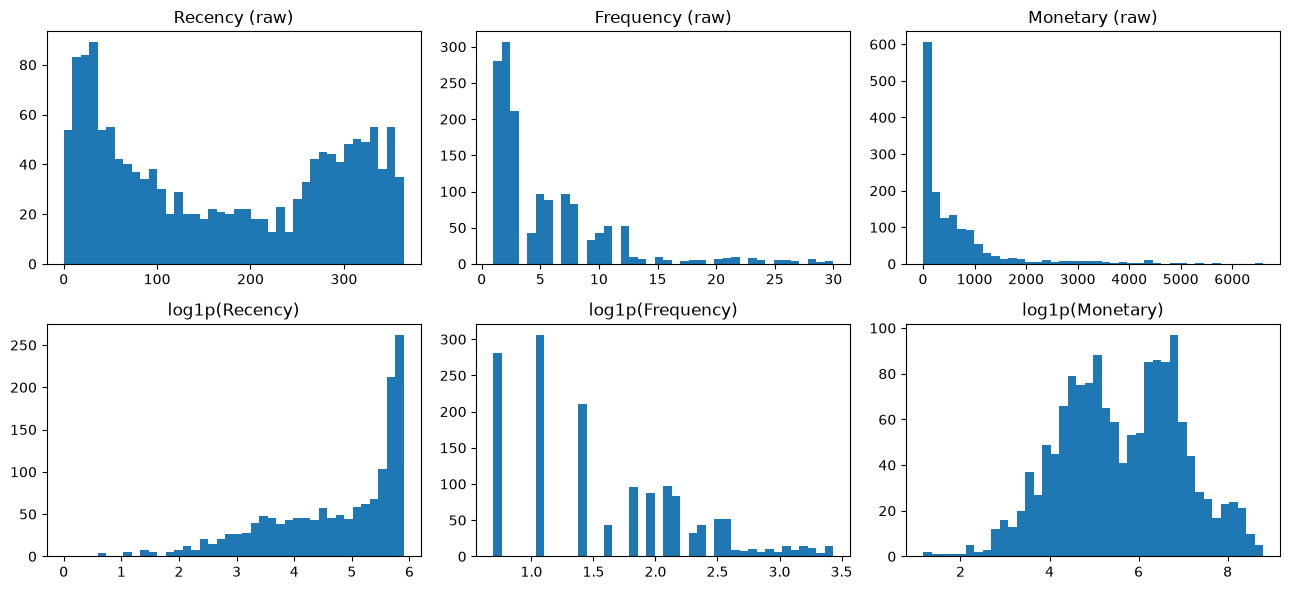

In [58]:
'''
The Top Row (Raw): Visualizes Recency, Frequency, and Monetary in their raw forms, 
clearly showing the heavy right-skew (massive clusters jammed on the left, long stretched tails to the right).

The Bottom Row (Log): Visualizes the same metrics after applying np.log1p(), 
proving visually how nicely the data transforms into cleaner, bell-curve-like distributions for machine learning.
'''
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for j, col in enumerate(["Recency", "Frequency", "Monetary"]):
    axes[0, j].hist(fm[col], bins=40);            axes[0, j].set_title(f"{col} (raw)")
    axes[1, j].hist(fm[f"log_{col}"], bins=40);   axes[1, j].set_title(f"log1p({col})")
fig.tight_layout(); fig.savefig("01_distributions.png", dpi=120)

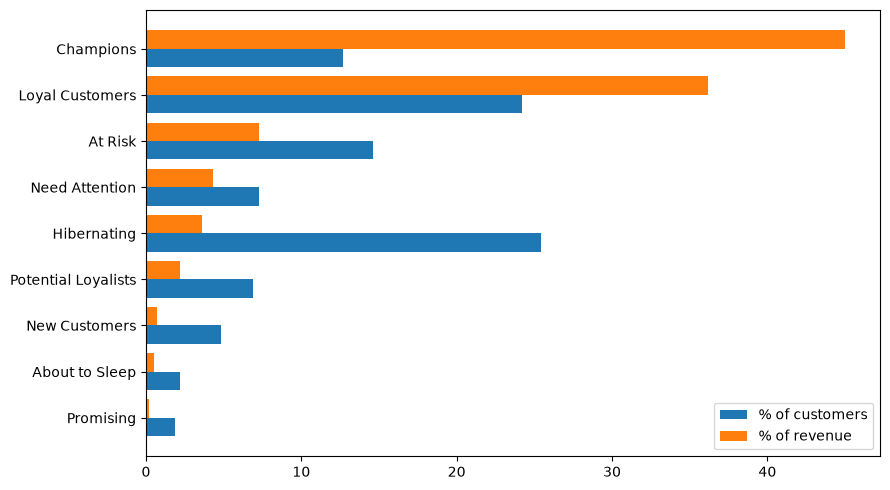

In [59]:
order = summary.sort_values("pct_revenue")
y = np.arange(len(order)) #0 to 9
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(y - 0.2, order["pct_customers"], height=0.4, label="% of customers")
ax.barh(y + 0.2, order["pct_revenue"],   height=0.4, label="% of revenue")
ax.set_yticks(y, labels=order.index); ax.legend()
fig.tight_layout(); 

In [60]:
fm['Monetary'].quantile([.01, .05, .5, .95, .99])

0.01      13.1348
0.05      30.2260
0.50     260.0950
0.95    2772.5515
0.99    4426.9410
Name: Monetary, dtype: float64

In [61]:
fm['Monetary'].skew()              # skewness


np.float64(2.9328500755934264)

In [62]:
fm['Monetary'].kurt()              # excess kurtosis


np.float64(9.955951764227757)

In [63]:
fm['Monetary'].describe()          # count, mean, std, min, quartiles, max


count    1500.000000
mean      623.971573
std       916.706847
min         2.190000
25%        96.782500
50%       260.095000
75%       763.770000
max      6595.940000
Name: Monetary, dtype: float64

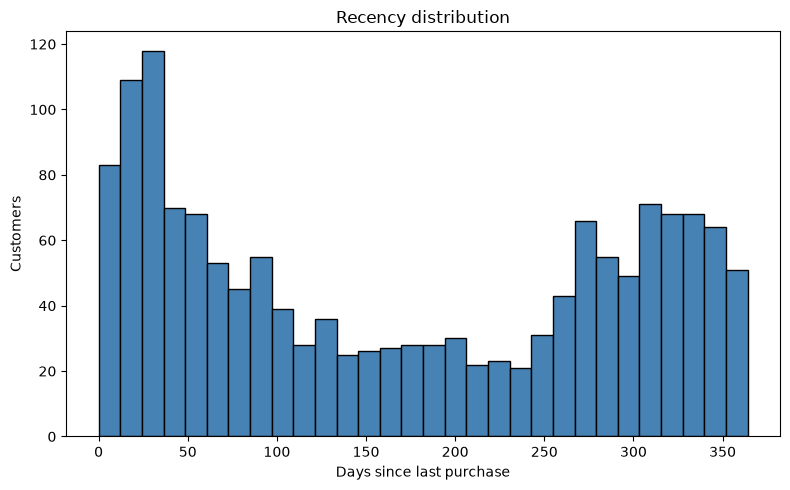

In [64]:
### Example: A Clean Single Plot

import matplotlib.pyplot as plt

# 1. Create the blank canvas (fig) and one plot (ax)
fig, ax = plt.subplots(figsize=(8, 5))

# 2. Draw the histogram onto that specific 'ax'
ax.hist(fm['Recency'], bins=30, color='steelblue', edgecolor='black')

# 3. Customize the 'ax'
ax.set_title('Recency distribution')
ax.set_xlabel('Days since last purchase')
ax.set_ylabel('Customers')

# 4. Clean up the padding and save the 'fig' canvas
fig.tight_layout()
fig.savefig('recency.png', dpi=150)
plt.show()


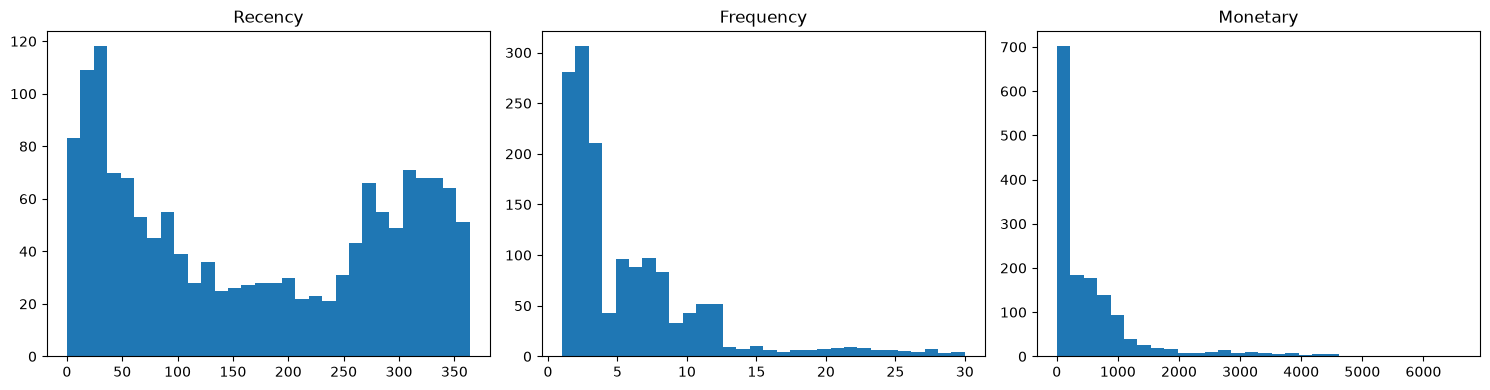

In [65]:
# Create a canvas with 1 row and 3 columns of plots
fig, axes = plt.subplots(1, 3, figsize=(15, 4))      

# 'axes' is now an array of 3 separate plot objects. 
# We can loop through them alongside our column names using zip()
for ax, col in zip(axes, ['Recency', 'Frequency', 'Monetary']):
    ax.hist(fm[col], bins=30)
    ax.set_title(col)

fig.tight_layout()

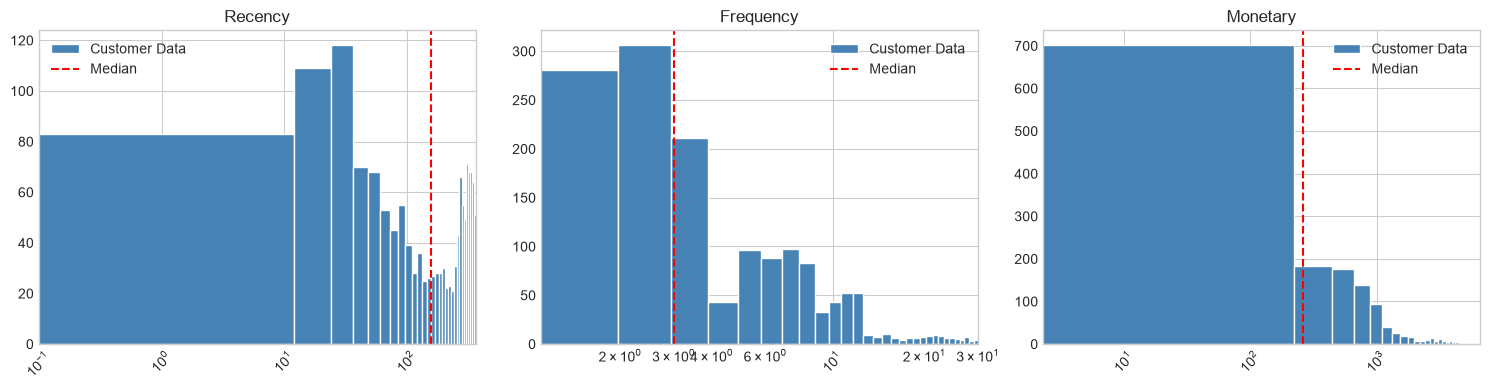

In [66]:
import matplotlib.pyplot as plt

# 1. Apply the global theme (must be done before creating the figure)
plt.style.use('seaborn-v0_8-whitegrid')

# Create a canvas with 1 row and 3 columns of plots
fig, axes = plt.subplots(1, 3, figsize=(15, 4))      

for ax, col in zip(axes, ['Recency', 'Frequency', 'Monetary']):
    # Added a 'label' here so the legend knows what to call the bars
    ax.hist(fm[col], bins=30, color='steelblue', edgecolor='white', label='Customer Data')
    
    # 2. Draw a vertical line for the median
    median_val = fm[col].median()
    ax.axvline(median_val, color='red', linestyle='--', label=f'Median')
    
    # 3. Convert the x-axis to a logarithmic scale to compress the right-skew
    ax.set_xscale('log')
    
    # 4. Force the axis limits to zoom tightly around the actual data
    # (Adding a tiny offset to the minimum because log scale cannot handle absolute 0)
    ax.set_xlim(fm[col].min() + 0.1, fm[col].max())
    
    # 5. Rotate the x-axis tick labels by 45 degrees to prevent overlapping
    ax.tick_params(axis='x', rotation=45)
    
    # 6. Display the legend box so the viewer knows what the red line is
    ax.legend()
    
    ax.set_title(col)

fig.tight_layout()

In [67]:
import seaborn as sns

In [68]:
sns.set_theme(style='whitegrid')

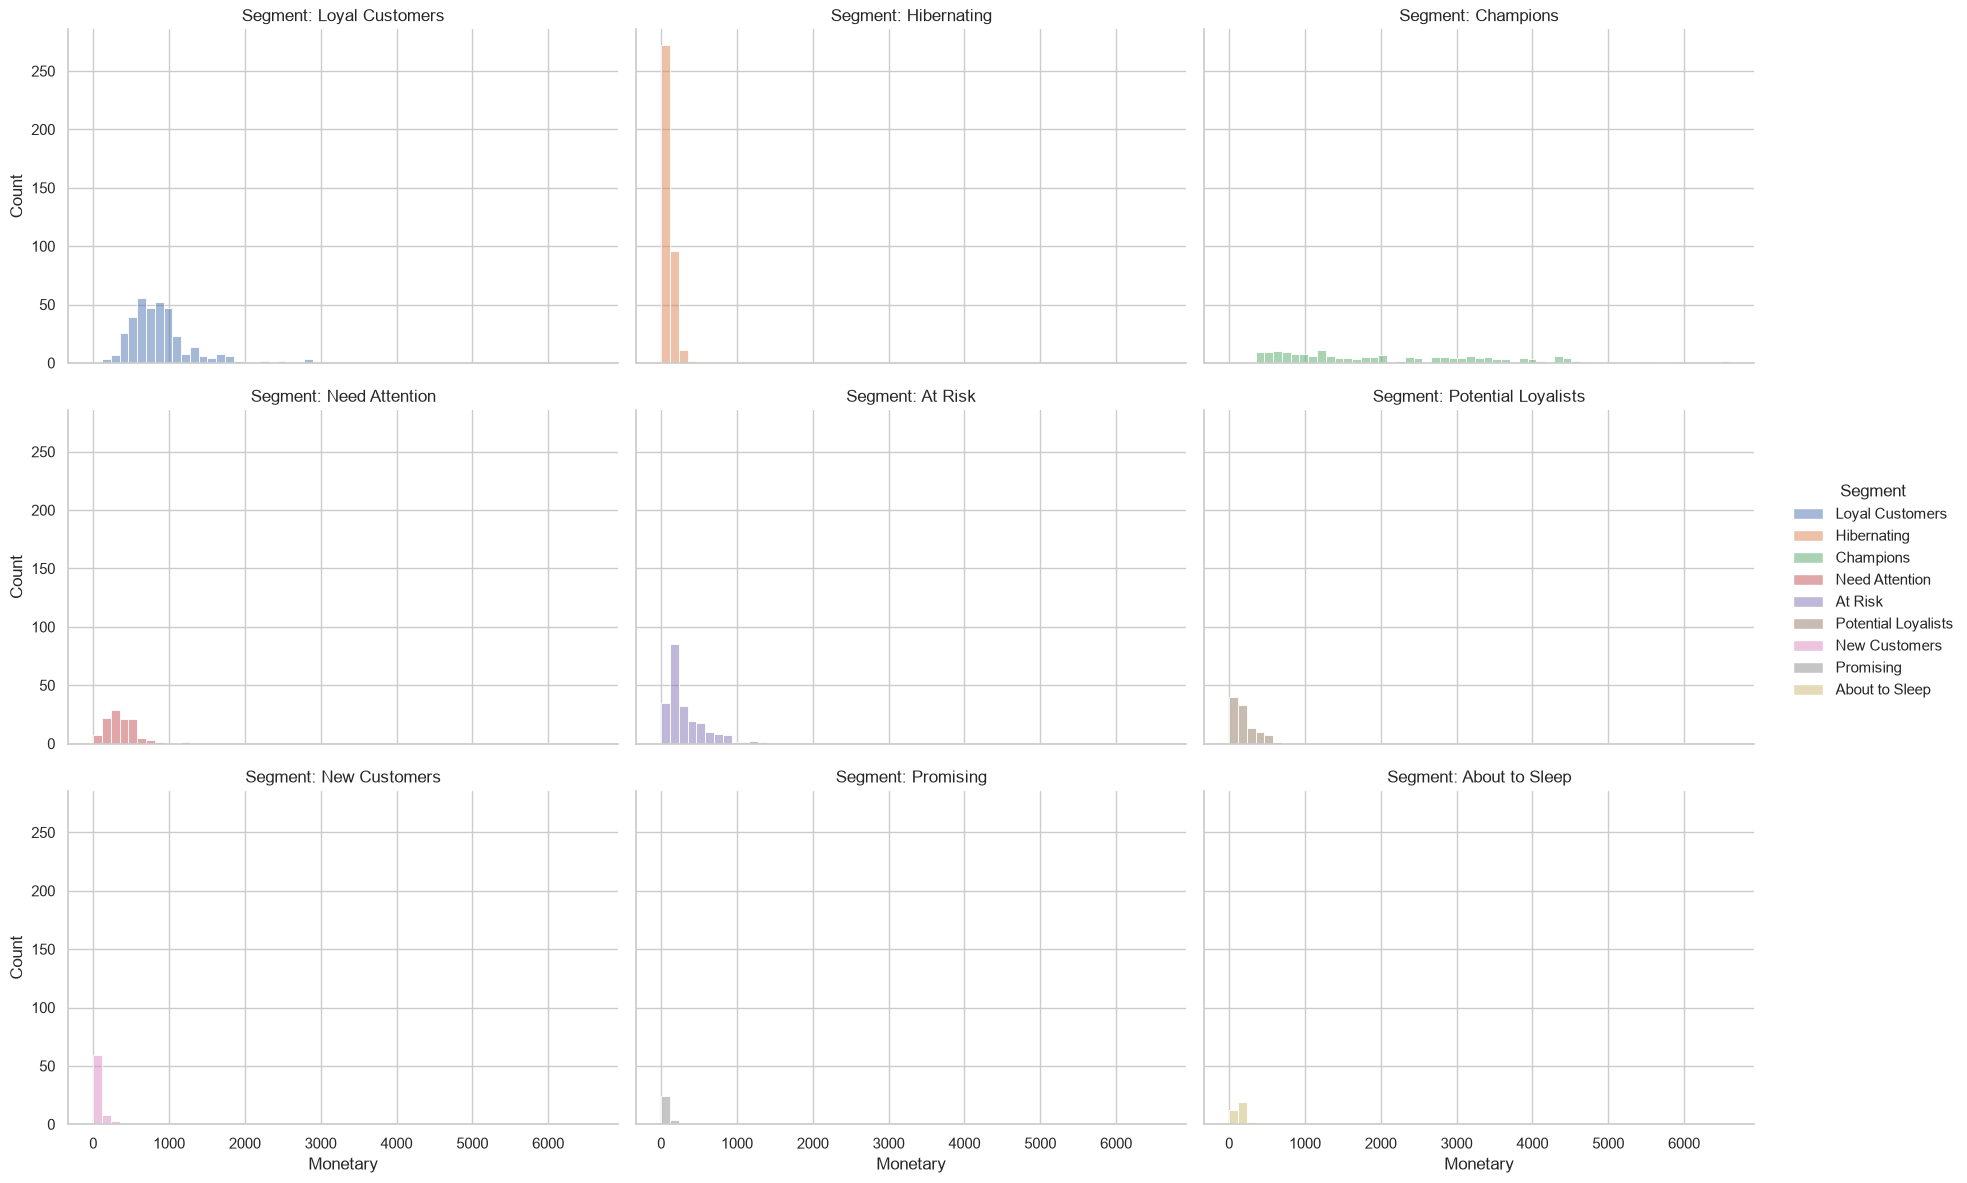

In [69]:
# 1. You DO NOT build a figure. Seaborn does it for you.
# By adding col='Segment', Seaborn automatically creates a grid with one plot per segment!
g = sns.displot(data=fm, x='Monetary', col='Segment',hue='Segment', col_wrap=3, height=4, aspect=1.5)

# 2. You customize it using the returned FacetGrid object ('g'), NOT Matplotlib 'ax' commands
g.set_titles("Segment: {col_name}")

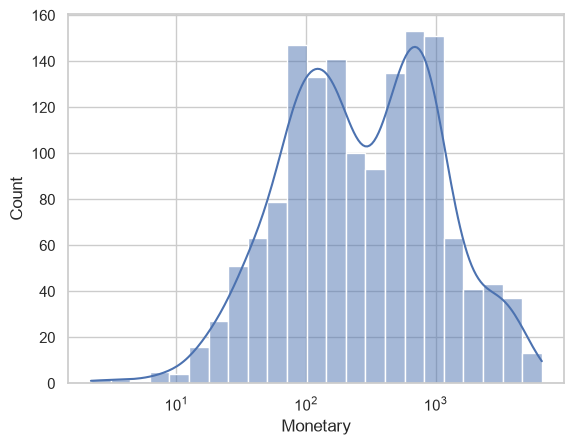

In [70]:
f= sns.histplot(data=fm, x='Monetary', log_scale=True, kde=True)   


<Axes: xlabel='Monetary', ylabel='Count'>

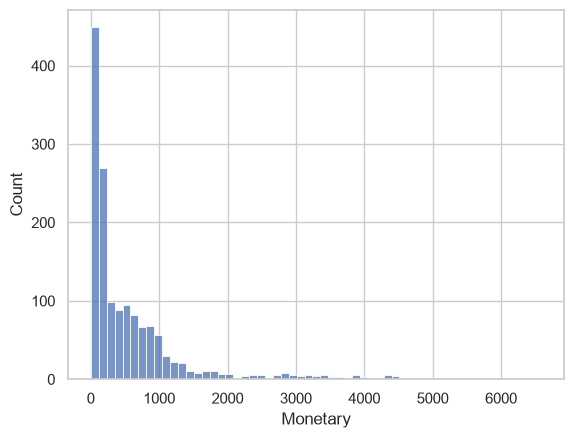

In [71]:
sns.histplot(data=fm, x='Monetary')

<Axes: xlabel='Monetary', ylabel='Count'>

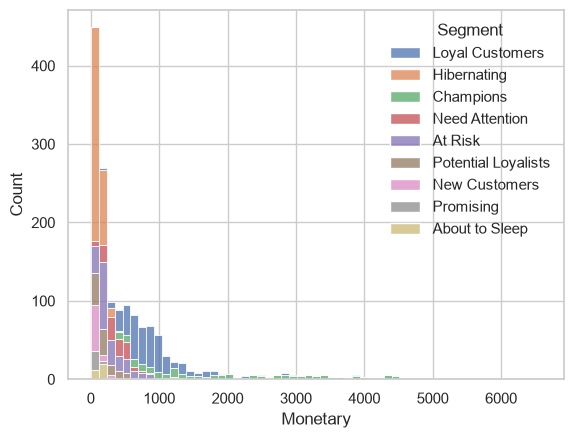

In [72]:
sns.histplot(data=fm, x='Monetary', hue='Segment', multiple='stack',stat="count")


<Axes: xlabel='Recency', ylabel='Density'>

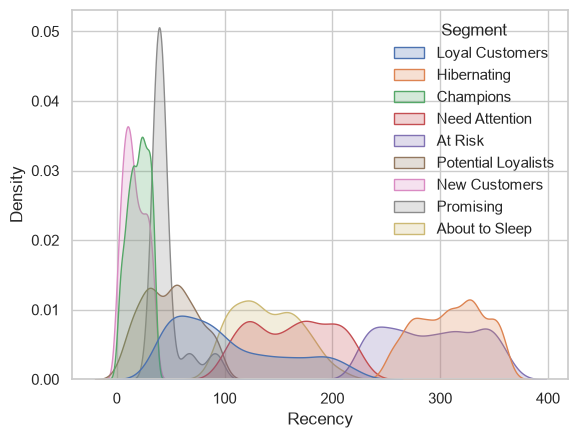

In [73]:
sns.kdeplot(data=fm, x='Recency', hue='Segment', common_norm=False, bw_adjust=0.8, fill=True)


<Axes: xlabel='Recency', ylabel='Proportion'>

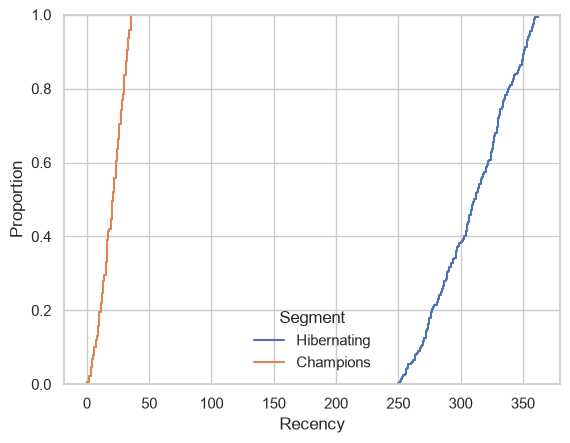

In [74]:
sns.ecdfplot(data=fm[fm['Segment'].isin(['Champions', 'Hibernating'])], x='Recency', hue='Segment')


<Axes: xlabel='Segment', ylabel='Monetary'>

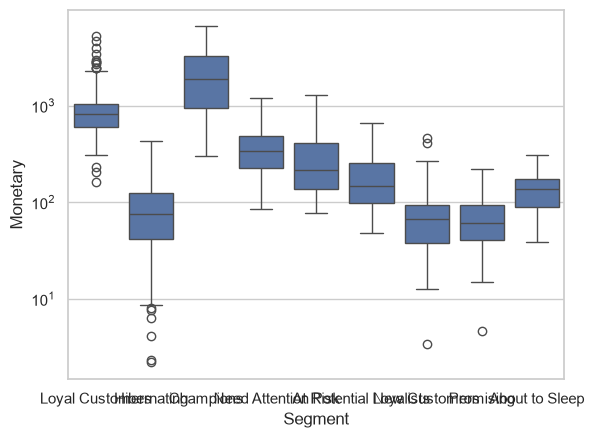

In [75]:
sns.boxplot(data=fm, x='Segment', y='Monetary', log_scale=True)

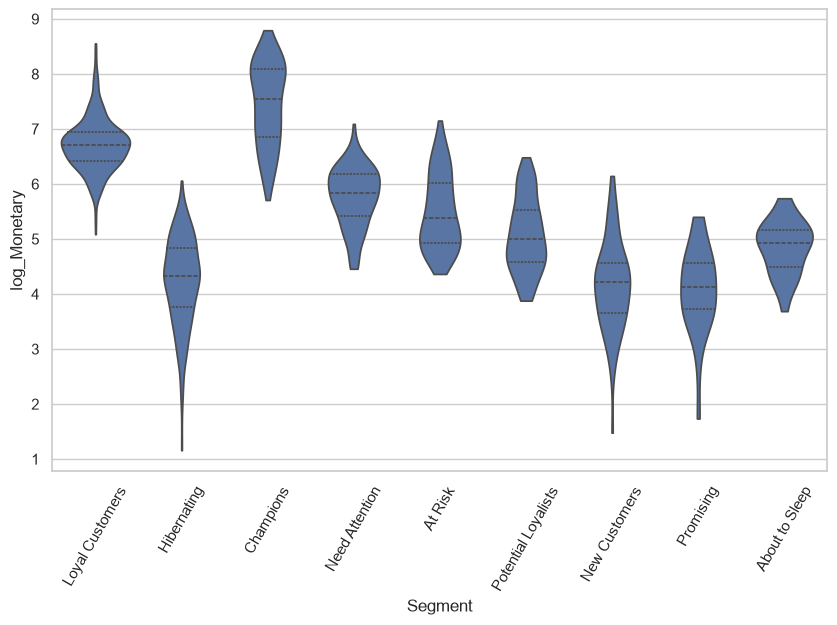

In [76]:
fig, ax = plt.subplots(figsize=(10, 6))

# 2. Tell Seaborn to stick the plot exactly onto that 'ax'
sns.violinplot(data=fm, x='Segment', y='log_Monetary', cut=0, inner='quartile', ax=ax)

# 3. Now the rotation will work perfectly
ax.tick_params(axis='x', rotation=60)

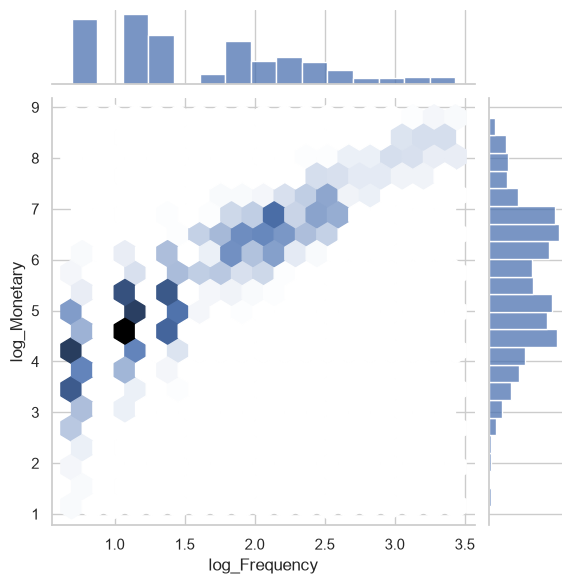

In [77]:
sns.jointplot(data=fm, x='log_Frequency', y='log_Monetary', kind='hex')    # scatter/hex + marginal histograms

<Axes: xlabel='log_Frequency', ylabel='log_Monetary'>

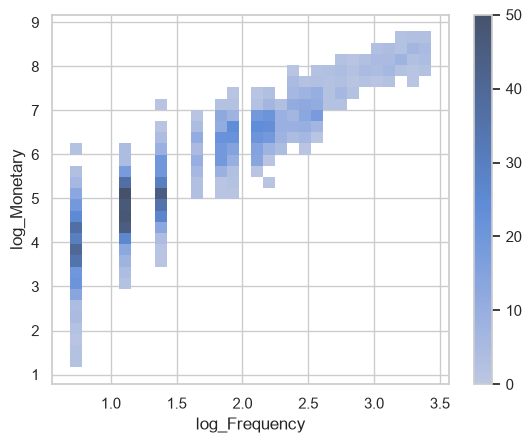

In [78]:
sns.histplot(data=fm, x='log_Frequency', y='log_Monetary', bins=30, cbar=True)


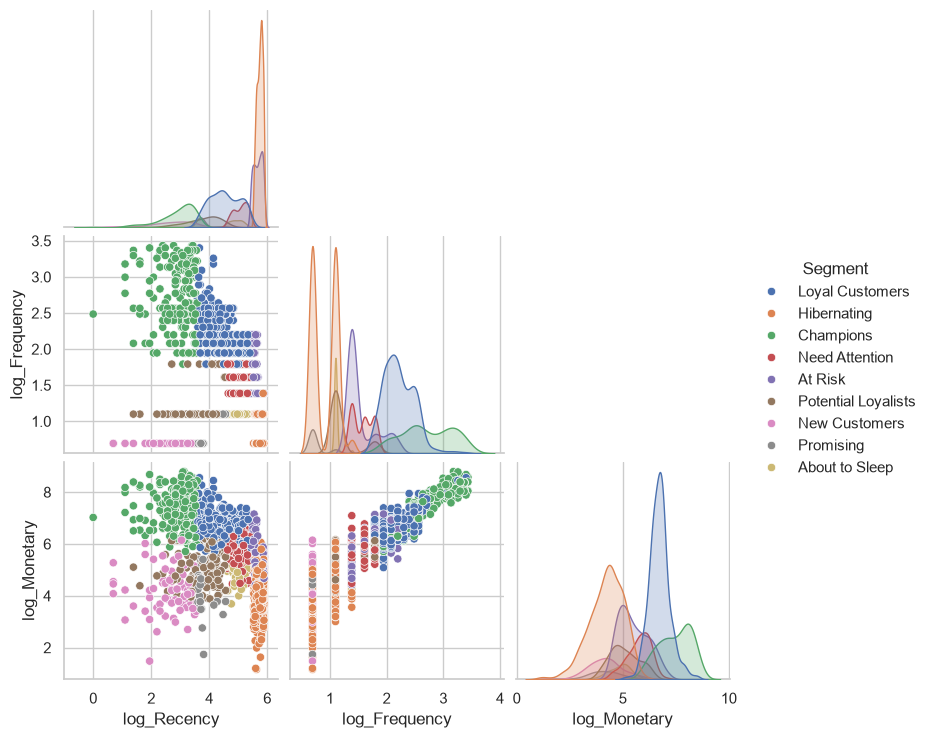

In [79]:
sns.pairplot(fm, vars=['log_Recency', 'log_Frequency', 'log_Monetary'], hue='Segment', corner=True)

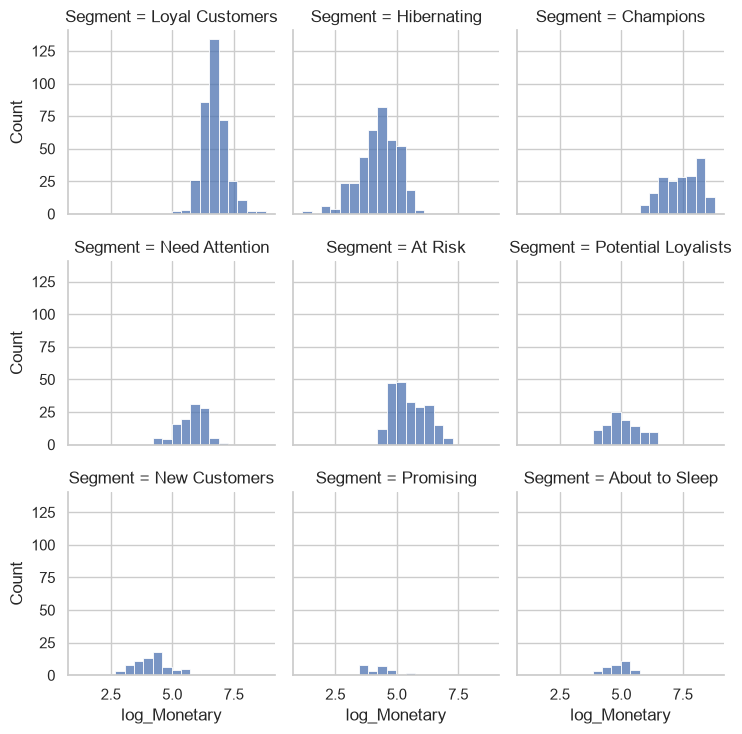

In [80]:
sns.displot(data=fm, x='log_Monetary', col='Segment', col_wrap=3, bins=20, height=2.5)

((array([-3.31270533, -3.05604344, -2.91334469, ...,  2.91334469,
          3.05604344,  3.31270533], shape=(1500,)),
  array([1.16002092, 1.19996478, 1.47932923, ..., 8.67918108, 8.77842143,
         8.79436118], shape=(1500,))),
 (np.float64(1.3582455560303297),
  np.float64(5.600804821836912),
  np.float64(0.9955806102446945)))

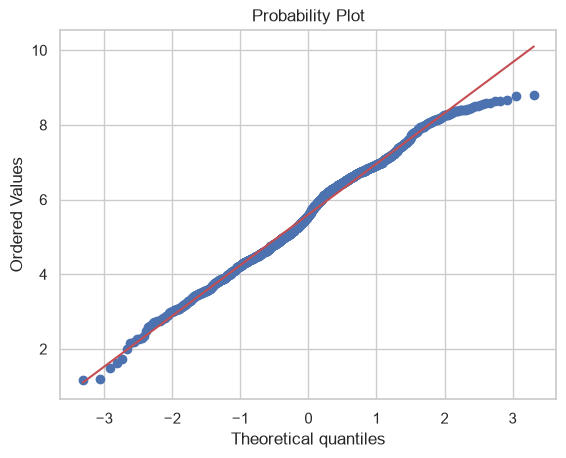

In [81]:
from scipy import stats
stats.probplot(fm['log_Monetary'], dist='norm', plot=plt)

<Axes: >

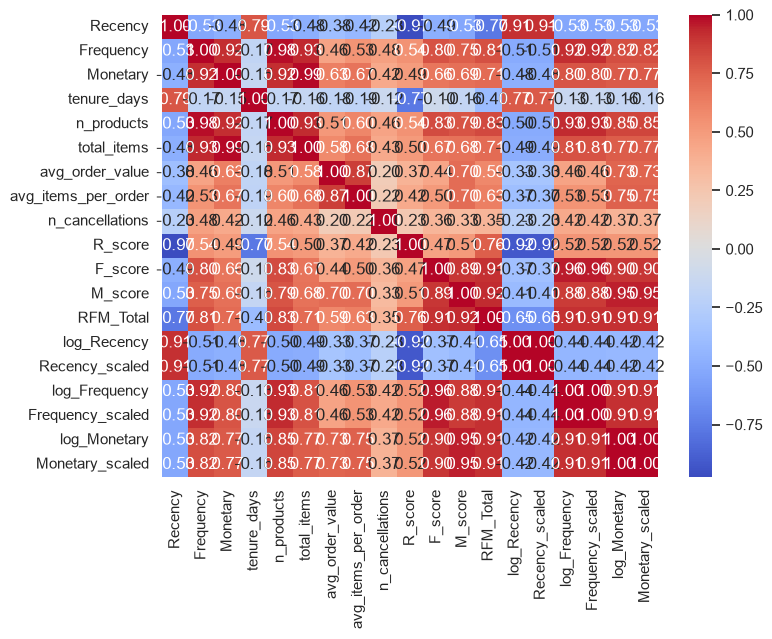

In [82]:
# 1. df.corr() calculates the math. 
# numeric_only=True is REQUIRED, otherwise Pandas will crash trying to multiply strings like "Champions"
corr_matrix = fm.corr(numeric_only=True)

# 2. Draw the heatmap
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", ax=ax)

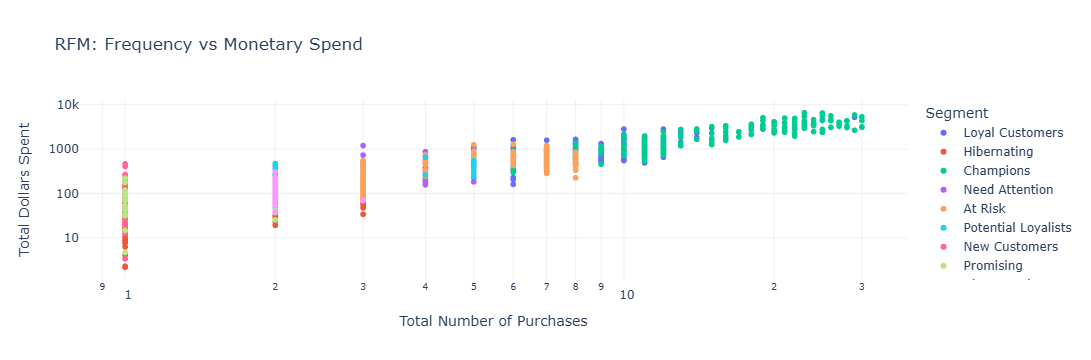

In [83]:
import plotly.express as px

fig = px.scatter(
    fm, 
    x='Frequency', 
    y='Monetary',
    color='Segment',
    
    # 1. Instantly log-scale the axes (no np.log1p or ax.set_xscale needed!)
    log_x=True, 
    log_y=True,
    
    # 2. Add titles and clean up ugly DataFrame column names for the viewer
    title="RFM: Frequency vs Monetary Spend",
    labels={
        'Frequency': 'Total Number of Purchases', 
        'Monetary': 'Total Dollars Spent'
    },
    
    # 3. Apply a clean background theme (no sns.set_theme needed)
    template='plotly_white'
)
fig.show()

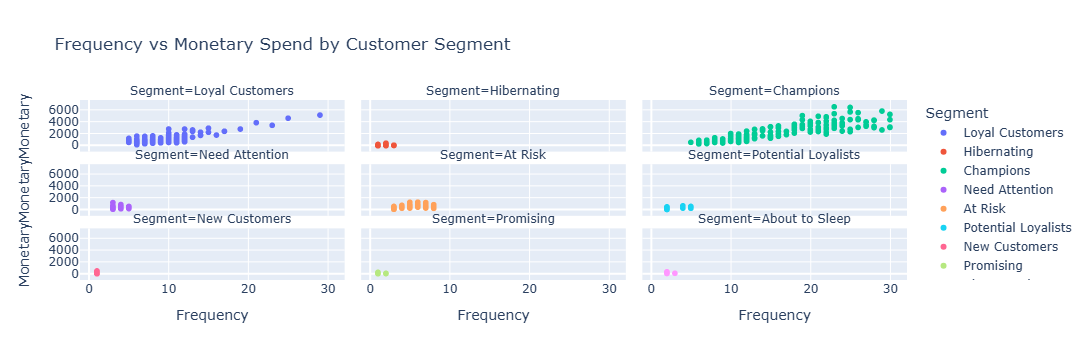

In [84]:
import plotly.express as px

# Create a grid of scatter plots, one for each Segment
fig = px.scatter(
    fm, 
    x='Frequency', 
    y='Monetary',
    color='Segment',          # Optional: Color-codes the dots by segment
    facet_col='Segment',      # This splits the data into separate charts based on Segment
    facet_col_wrap=3,         # This forces a new row after exactly 3 charts
    title='Frequency vs Monetary Spend by Customer Segment'
)

# Display the interactive grid in the output
fig.show()

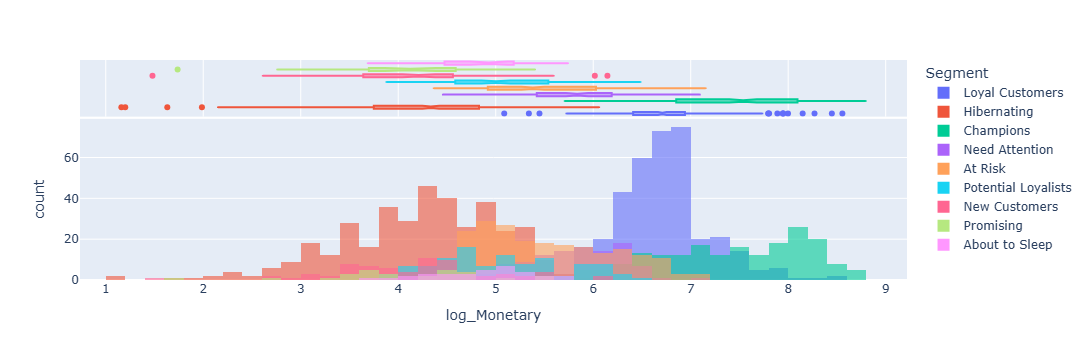

In [85]:
px.histogram(fm, x='log_Monetary', color='Segment', nbins=40, 
             barmode='overlay', opacity=0.6, marginal='box')

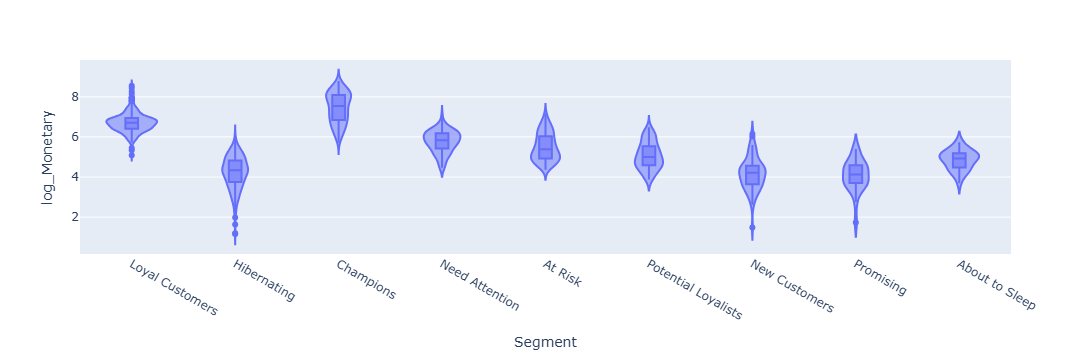

In [86]:
px.violin(fm, x='Segment', y='log_Monetary', box=True)


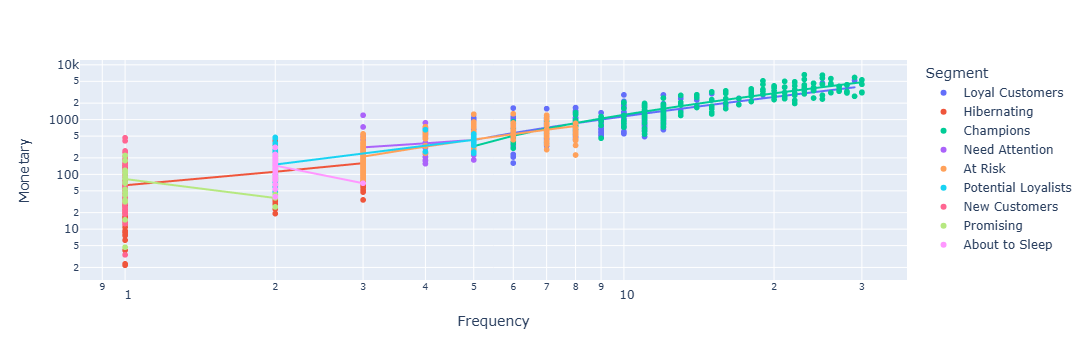

In [87]:
px.scatter(fm, x='Frequency', y='Monetary', color='Segment', 
           log_x=True, log_y=True, 
           hover_name='CustomerID', hover_data=['R_score', 'F_score', 'M_score'],trendline='ols')

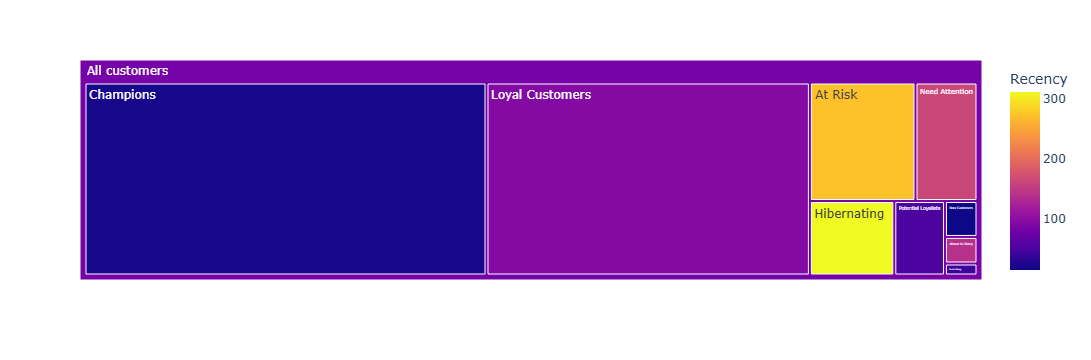

In [88]:
px.treemap(fm, path=[px.Constant('All customers'), 'Segment'], 
           values='Monetary', color='Recency')

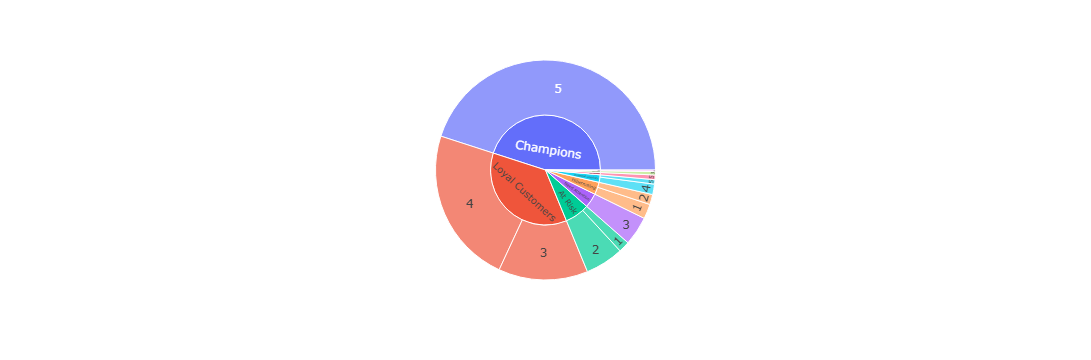

In [89]:
px.sunburst(fm, path=['Segment', 'R_score'], values='Monetary')


In [90]:
pip install dash

Note: you may need to restart the kernel to use updated packages.
